In [1]:
import numpy as np
import matplotlib.pyplot as plt

# **What determines whether a gene spreads or disappears?**

## Mathematical modeling and Python simulations of population genetics

### 1. Introduction

#### 1.1 The problem
The rapid advancement of technology enables us to transform real-world objects into models that can be studied in detail by modifying them and observing their behavior in an isolated environment. The most practical application of such concepts lies in the field of biology, allowing for the study of human genes through the simulation of their behavior and characteristics, testing under extreme conditions and so on. 

It is clear that some genetic variants become more common in a population, while others become less common or disappear completely. This may seem like something predictable - e.g. if one allele has an advantage we might expect it to become more common over time. However, populations are not deterministic systems and random events can influence which alleles are passed to the next generation. 

In this project, I am investigating an interesting mathematical question:

***Can mathematics predict how an allele will spread through a population?***

My survey uses a simple mathematical model and Python simulations.

#### 1.2 Research question

The main reserach question of this project is:

***How accurately can mathematical models predict the spread or disappearance of an allele, and how do population size, initial allele frequency, genetic drift and natural selection affect this prediction?***

The main topic includes many components that have to be studied carefully, so the survey is based on several smaller questions:

>* How does population size affect genetic drift?
>* Does the initial frequency of an allele affect its chance of becoming fixed or disappearing?
>* How does natural selection affect allele frequency?
>* How different are deterministic and stochastic models?
>* Can we predict an exact evolutionary trajectory or only probabilities and statistical properties?


#### 1.3 Result predictions
1. Larger populations are expected to show smaller fluctuations in allele frequency between generations
2. An allele with higher initial frequency is expected to have bigger chance of becoming fixed
3. An allele with higher fitness is expected to have bigger chance of becoming fixed
4. In the absence of selection, an allele is expected to have a probability of fixation close to its initial frequency
5. Increasing the strength of natural selection in favor of an allele is expected to increase its probability of becoming fixed


#### 1.4 Project map
1. Introducing biological concepts of allele frequency, genetic drift and natural selection
2. Creating mathematical model 
3. Working with Deterministic model
4. Working with Stochastic model
5. Performing experiments by changing model's parameters
6. Analyzing results

### 2. Biological background

#### 2.1 Allele

An allele is one version of a gene. For example, the color of person's eyes is a gene, while black, brawn, blue are the alleles for this specific gene. For the purposes of this project, I will use two abstract alleles:
***A*** and ***a***. 

#### 2.2 Allele frequency

Allele frequency describes how common an allele is in a population. If there are 100 copies of an allele (that means that our population consist of 100 individuals) and 30 of them are ***A***, then $$p_\text{A} = \frac{30}{100} = 0.30$$
Therefore, the allele frequency of allele ***A*** is 30%. In this case there are two mutually exclusive outcomes (the allele is either ***A*** or ***a***) so the single allele selection perfectly describes a Bernoulli trial (this is a random experiment that has exactly two possible outcomes called "success" and "failure"). The total probability equals one and the frequency of the other allele (***a***) is then $$p_\text{a} = 1-p_\text{A}$$ In our example that means 0.70 or 70%. One of the main variables being tracked by my project will be namely allele frequency. 






In [3]:
#Allele frequencies at starting generation
p_0 = 0.5
q_0 = 1- p_0
print("Initial frequency of allele A: ", p_0)
print("Initial frequency of allele a: ", q_0)

Initial frequency of allele A:  0.5
Initial frequency of allele a:  0.5


#### 2.3 Allele fitness

Allele fitness measures the reproductive success of one allele when shuffled across the various genetic backgrounds of a population. Alleles with higher biological fitness leave more copies in the next generation, while low-fitness alleles are gradually eliminated. The meaning of this parameter may be presented as the score of how successfully a specific gene passes into the next generation. 

#### 2.4 Genetic drift

Genetic drift means a random change in allele frequency. Even if two alleles have the same biological fitness, their frequencies may change because of random sampling. For example, if the initial frequency of ***A*** is as follows: $$p_\text{A} = 0.5$$ after one generation, random sampling could give the result $$p_\text{A} = 0.56$$ <br> After many generations, the frequency could eventually reach 1, which means that ***A*** has become fixed. Alternatively, it could reach 0, which means that ***A*** has completely disappeared. <br> Important feature of genetic drift is that it is stronger in smaller populations, as we can observe: If one individual in a population of 10 individuals dies before it leaves any genetics to the next generation, 10% of this population's gene pool is irreversaly lost[[1]](#ref1). Meanwhile in a generation of 100 individuals, one individual's death means losing 1% genetical information. 

#### 2.5 Natural selection

Natural selection may also result in changes in allele frequency along with genetic drift. The environment determines whether an allele increases or decreases in a population over time, depending on the phenotype it expresses[[1]](#ref1). This can be represented using a selection coefficient $s$ and define the fitness of allele ***A*** as $$w_\text{A} = 1+s$$ while allele ***a*** has fitness 1. This means that ***A*** has a small advantage over ***a***. The larger the value of ***s*** is, the stronger the effect of selection is. 

In [5]:
selection_strength = 0.05
fitness_A = 1 + selection_strength
fitness_a = 1
print(f"Allele A has {fitness_A-fitness_a} higher fitness than allele a with selection strength {selection_strength}")


Allele A has 0.050000000000000044 higher fitness than allele a with selection strength 0.05


Natural selection and allele fitness are tightly coupled. While natural selection acts like an enviromental pressure, the fitness of the allele determines how likely it will continue to spread into the next generation under its influence.

### 3. Mathematical model

#### 3.1 Population parameters

Assuming that a population contains of $N$ diploid individuals (meaning that each individual has two copies of the gene) the total number of allele copies is $2N$. 



In [6]:
population_size = 100
allele_copies = 2*population_size
number_of_generations = 500
print(f"Population of {population_size} diploid individuals has {allele_copies} copies of allele A")

Population of 100 diploid individuals has 200 copies of allele A


If $t$ represents the generation number, then $X_t$ will be the number of copies of allele ***A*** in generation $t$. The relationship between allele frequency and the number of ***A*** copies is as follows [[2]](#ref2): $$p_t = \frac{X_t}{2N}$$ Therefore $$X_t = 2*N*p_t$$ For example if $N$ is 100 and $p_0 = 0.5$ then the expected number of ***A*** copies is $$X_0 = 2*100*0.5 = 100$$

In [9]:
initial_frequency = 0.5
A_copies = initial_frequency * allele_copies
print(f"Initial allele frequency of {initial_frequency} gives us {A_copies} expected copies of allele A in generation of {population_size} individuals")

Initial allele frequency of 0.5 gives us 100.0 expected copies of allele A in generation of 100 individuals


### 4. Probability and Binomial distribution

#### 4.1 Binomial distribution 

This is the key mathematical idea that lies behind the used stochastic model. It summarizes the likehood that a value will take one of two independent values under a given number of parameters. As I mentioned earlier, when calculating allele frequency a single Bernoulli trial is used. Binomial distribution in fact models the probability of getting a certain number of successes in a sequence if Bernoulli trials. 

#### 4.2 Stochastic model 

A stochastic model is used to estimate the probability of various outcomes when random variables are present, incorporating randomness and uncertainty. This means running the same model multiple times will yield different results, which represents real-world unpredictability. 

As I mentioned in the previous section, the frequency of allele ***A*** in generation $t$ is labeled as $p_t$. Therefore, the number of ***A*** copies in next generation is modeled as follows: $$X_{t+1}\sim Binomial(2N, p_t)$$  This means that $X_{t+1}$ is a random variable. $2N$ and $p_t$ are important parameters for Binomial distribution, as $2N$ represents the total number of genes being examined and $p_t%$ represents the probability of allele ***A*** succeeding in each trial. The probability of obtaining $k$ copies of ***A*** is[[3]](#ref3): $$P(X=k)=\binom{2N}{k} p^k(1-p)^{2N-k}$$

In [14]:
number_of_A = np.random.binomial(allele_copies,initial_frequency)
print("Random number of A copies: ", number_of_A)
new_frequency = number_of_A/allele_copies
print("New frequency of A: ", new_frequency)

Random number of A copies:  95
New frequency of A:  0.475


*Note that the number of A copies changes each time the cell is executed. Respectively, the frequency also changes.*

The question here is *why*? How do we know that this formula represents the probability of specific allele spread? <br>
Since $k$ is defined as the number of successes (the number of copies of allele ***A***), then out of $n$ total trials $n-k$ is the number of unsuccessfull outcomes. If $p$ is the probability of a single success, then the probability of obtaining $k$ successes and $n-k$ failures in a specific order is $p \cdot p\cdot \ldots \cdot p$ ($k$ times) and $(1-p)\cdot(1-p)\cdot \ldots \cdot(1-p)$ ($n-k$ times). Since all trials are independent, the probability of this specific sequence is: $$p^k(1-p)^{n-k}$$
However, successfull trials don't have to be ordered one after another. There are multiple different ways to obtain these $k$ successes across $n$ total trials. Since they can't be repeated and selection order doesn't matter this is a combination: $$\left(\begin{array} {c} n \\ k\end{array} \right) = \frac{n!}{k!(n-k)!} $$ The probability for a single sequence to occur has to be multiplicated by the total number of possible successfull sequences. Then the probability of having $k$ copies of allele ***A*** is simply: $$P(X=k)=\binom{2N}{k} p^k(1-p)^{2N-k}$$

### 5. Expected value and variance

The most likely outcome the used stochastic model would give us if the process is repeated many times is in general represented as follows[[3]](#ref3): $$E[X] = n \cdot p$$ In my model $n$ is actually $2N$ as it represents the total number of gene copies and $p$ is the current frequency of allele - $p_t$. 
Because a stochastic model is used, the actual number of gene copies in the next generation won't always equal the expected value due to random chance. The variance is in general calculated with the following formula: $$Var(X) = n\cdot p\cdot(1-p)$$ and in my specific model it transforms as follows: $$Var(X) = 2N \cdot p_t \cdot (1-p_t)$$

In [8]:
expected_value = allele_copies*initial_frequency
variance = (allele_copies*initial_frequency*(1-initial_frequency))
print("Expected number of A copies: ", expected_value)
print("Theoretical variance: ", variance)

Expected number of A copies:  100.0
Theoretical variance:  50.0


### 6. Deterministic model

The simplest possible model is the deterministic one. The difference between deterministic and stochastic model is that deterministic models rely on fixed rules and initial conditions, while stochastic models include randomness. Therefore, creating my deterministic model includes no selection, no mutation, no migration and no genetic drift. <br> *Note: In nature deterministic models can't describe allele dynamics - it is strongly influenced by randomness.* <br> Allele frequency also remains the same. Therefore $p_{t+1} = p_t$. If $p_0 = 0.5$ then $p_1=p_2=p_3=\dots=0.5$

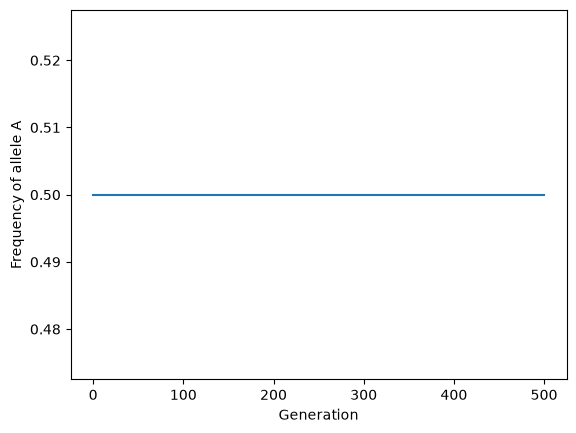

In [9]:
deterministic_frequency = initial_frequency
deterministic_frequencies = []
for generation in range(number_of_generations+1):
    deterministic_frequencies.append(deterministic_frequency)

plt.plot(deterministic_frequencies, label="Deterministic model")
plt.xlabel("Generation")
plt.ylabel("Frequency of allele A")
plt.show()


### 7. Stochastic model
As I mentioned previously stochastic model incorporates probability distributions into the process. Including genetic drift the mathematical model becomes $X_{t+1}\sim Binominal(2N,p_t)$ and $p_{t+1}= \frac{X_{t+1}}{2N}$. <br>This makes the difference between the deterministic and the stochastic model obvious: in the deterministic one $p_{t+1}=p_t$. In the stochastic one $p_{t+1}$ is generated randomly. The main function (it is introduced in the next part - `simulate_population()` uses stochastic model in order to introudce the natural effect of "random" iheritance of genes in the nature. It is influenced not only by unpredictable events, but also by various forces, such as parameters I mentioned (genetic drift, natural selection), but also mutation, migration and so on. The binomial distribution does not directly determine allele frequencies, but simulates the random allele transmition between generations. This model structure allows to study how allele frequencies may change over time. 

### 8. Main implementation

In this chapter the mathematical variables are combined into one function in order to plot the dependence between allele frequency and other parameters in the following experiments with data such as population size, initial frequency and selection strength. 


In [10]:
def simulate_population(population_size, initial_frequency, generations = number_of_generations, selection = 0):
    allele_copies = 2*population_size
    frequency = initial_frequency
    population_frequencies = []

    for generation in range(generations):
        if selection != 0:
            frequency = (frequency*(1+selection))/(frequency*(1+selection)+(1-frequency))
        A_copies = np.random.binomial(allele_copies,frequency)
        current_frequency = A_copies/allele_copies
        population_frequencies.append(current_frequency)
        frequency = current_frequency
        if current_frequency==1 or current_frequency==0:
            population_frequencies.extend([current_frequency]*(generations-len(population_frequencies)))
    return population_frequencies


### 9. Experiment 1 - Population size
The first research question I am investigating is how does population size affect allele frequencies? My basic assumption is that in smaller generations there are stronger fluctations because one of the parameters that the stochastic process depends on is $2N$ (namely, the total number of allele copies, which are determined by the number of individuals). Also, in smaller generations the difference between allele frequencies should be more visible since the experiments are performed on a smaller set of objects, while in big populations the difference between allele frequencies shouldn't be so obvious. 


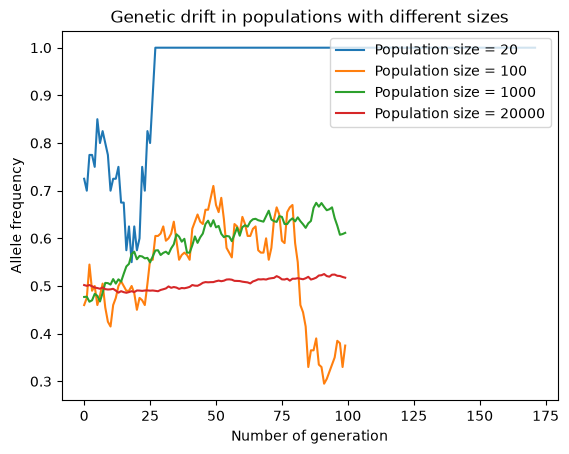

In [16]:
population_sizes = [20,100,1000,20000]
for size in population_sizes:
    current_population = simulate_population(size,initial_frequency,100)
    plt.plot(current_population, label = f"Population size = {size}")
plt.title("Genetic drift in populations with different sizes")
plt.legend(loc="upper right")
plt.xlabel("Number of generation")
plt.ylabel("Allele frequency")
plt.show()


The experiment proves my thesis that in smaller populations the "noise" (or the difference in allele frequency between generations) is more visible, while in bigger populations the function, presenting the dependence allele frequency-population size, leans to a straight line. What looks interesting is that this line tends to be close to the value of our initial frequency ($p_0=0.5$ in this case).

### 10. Experiment 2 - Initial frequency
This experiment requires to keep the population size constant. The parameter that gets changed is the initial frequency (the number of ***A*** allele copies in the first generation). The single simulation wouldn't be able to tell what is the probability of fixation(that's why repeated simulations are made as a part of the next experiments). But observing the function that was plotted in the experiment with different population sizes showed that allele frequency in bigger generations tends to be close to the initial value.

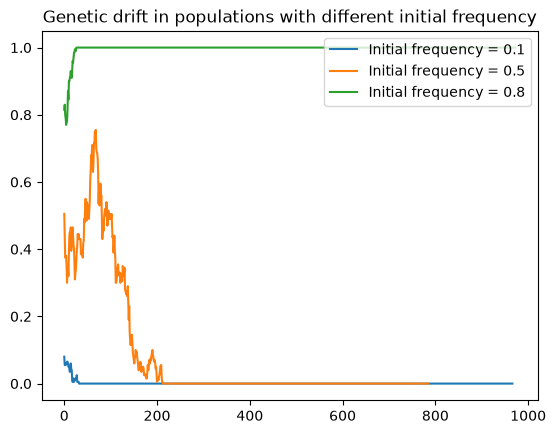

In [18]:
allele_frequencies = [0.1, 0.5, 0.8]
for frequency in allele_frequencies:
    current_population = simulate_population(population_size, frequency)
    plt.plot(current_population, label = f"Initial frequency = {frequency}")
plt.title("Genetic drift in populations with different initial frequency")
plt.legend(loc = "upper right")
plt.xlabel = "Number of generation"
plt.ylabel = "Allele frequency"
plt.show()

This experiment asserts what was already showed in the previous plot - initial allele frequency is the value, which can determine aproximately what is the frequency of this allele in the next generations. <br> What looks interesting is that the graph, representing $p_0$ = 0.1 often reaches zero, which means that allele ***A*** got extinct and its frequency remanied the same in the next generations. If no individual has allele ***A*** in its genes, then there is no way for ***A*** to be spread in the future, which is expected. Also, if every single individual in one population has the allele, then there is no other variance of the gene, represented by ***A***, that can be inherited. <br>This raises some interesting questions: Is it possible for a gene to completely lose one of its variances (which means an extinction of one allele and fixation of the other one)? What does this event depend on? 

#### 10.1 Allele fixation and extinction depending on allele frequency
In a closed population without new mutations fluctuation will not continue indefinitely and an allelle will eventualy reach one of two abssorbing boundaries: complete extinction or complete fixation. This depends fundamentally on it initial allele frequency[[5]](#ref5).<br>
In a model with no selective advantage the probability of allele reaching fixation is equal to its initial frequency. Random sampling process causes frequencies to bounce up and down unpredictably, but alleles starting near the lower boundary are far more likely to disappear from the gene pool. The most basic explanation is that in a fair genetic lottery all alleles have an equal chance of survivng and only one gene copy from the initial population will "win" and reach fixation. For example 10% initial frequency means owning 10% of the "lottery tickets". Therefore, if a specific allele holds some part of the gene pool at the start, its probability of fixation is exactly equal to that initial share. That's why allele fixation and extinction depend on the initial allele frequency.

### 11. Experiment 3 - Allele fitness
As i explained allele fitness means an allele having adavntage or disadvantage(determined by the environment), which determines its representation in the next generation. An important fact is that an individual wearing the allele with advantage is expected to be more reproductive. That leads to my main suggestion: allele with higher fitness is expected to have higher frequency in the next generations.

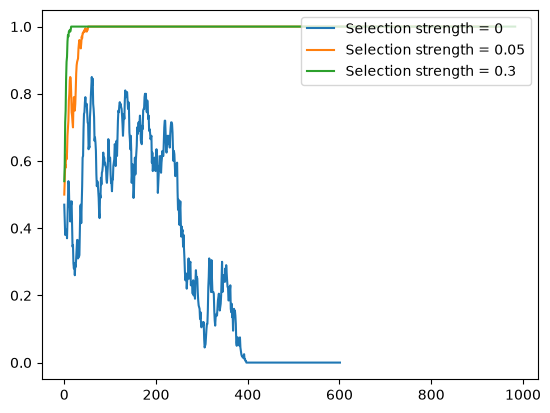

In [ ]:
allele_fitness = [0, 0.05, 0.3]
for fit in allele_fitness:
    current_population = simulate_population(population_size, initial_frequency,number_of_generations,fit)
    plt.plot(current_population,label = f"Fitness = {fit}")
plt.legend(loc="upper right")
plt.xlabel = "Number of generation"
plt.ylabel = "Allele frequency"
plt.show()

As expected, alleles with higher fitness have also higher chance of becoming fixed. What is also visible from the plot is that they become fixed earlier that those with lower seelction strength.

### 12. Repeated simulations
A single stochastic simulation is helpful in orther to observe my initial suggestions, regarding the parameters that allele frequencies depend on. In orther to estimate prbabilities many simulations are needed. 

#### 12.1 Repeating simulations with fixed parameters
Repeating population simulation with fixed initial frequency, population size and allele fitness allows to calculate the fixation probabililty by isolating random noise.

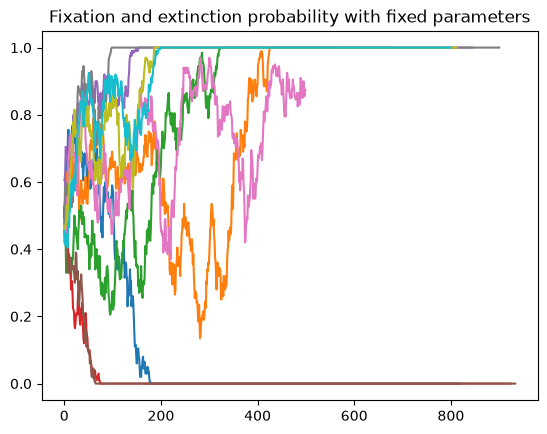

Fixation probability: 0.6
Extinction probability: 0.3


In [23]:
simulations = 10
fixations = 0
extinctions = 0
for simulation in range(simulations):
    frequencies = simulate_population(population_size=population_size,initial_frequency=initial_frequency)
    plt.plot(frequencies)
    final_frequency = frequencies[-1]
    if final_frequency == 1:
        fixations+=1
    elif final_frequency==0:
        extinctions+=1
plt.title("Fixation and extinction probability with fixed parameters")
plt.xlabel="Number of generation"
plt.ylabel="Allele frequency"
plt.show()
print(f"Fixation probability: {fixations/simulations}")
print(f"Extinction probability: {extinctions/simulations}")

#### 12.2 Repeating simulations with changing parameters

As showed in the previous chapter, testing the model with fixed parameters visualises the randomness of genetic drift through binomial distribution. Altering the initial frequency, population size and fitness thorugh rising or lowering values allows to look at the actual patterns that affect real-world allele spread. The main focus is on intial frequency and selection strength - which of them is more important and how do they depend on the population size.

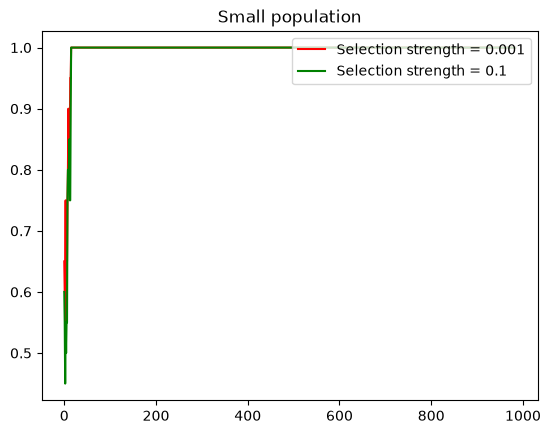

In [45]:
#Testing the model with small population and different selection strengths
test1 = simulate_population(population_size=10,initial_frequency=0.5, selection=0.001)
plt.plot(test1, label=f"Selection strength = 0.001", c='r')

test1 = simulate_population(population_size=10,initial_frequency=0.5, selection = 0.1)
plt.plot(test1, label=f"Selection strength = 0.1", c='g')

plt.title("Small population")
plt.legend(loc="upper right")
plt.show()

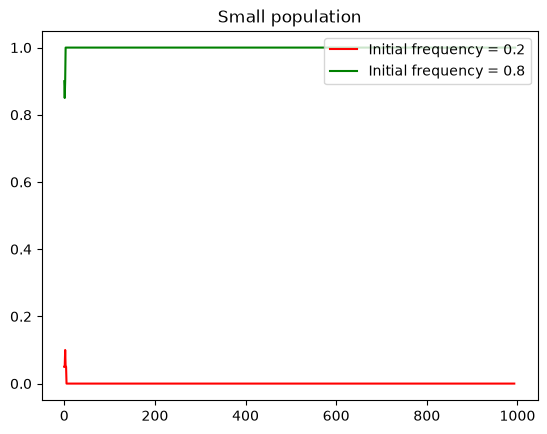

In [66]:
#Testing the model with small population and different initial frequencies
test1 = simulate_population(population_size=10,initial_frequency=0.2)
plt.plot(test1, label=f"Initial frequency = 0.2", c='r')

test1 = simulate_population(population_size=10,initial_frequency=0.8)
plt.plot(test1, label=f"Initial frequency = 0.8", c='g')

plt.title("Small population")
plt.legend(loc="upper right")
plt.show()

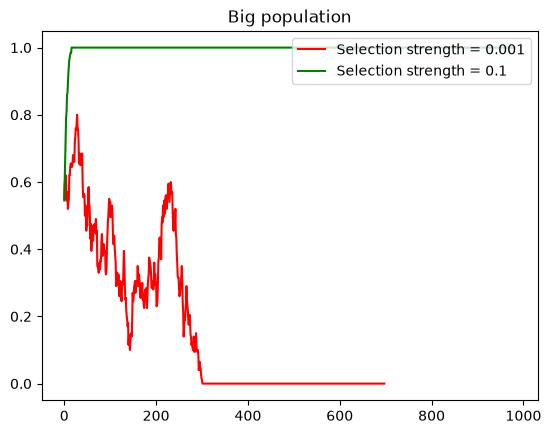

In [52]:
#Testing the model with big population and different selection strengths
test1 = simulate_population(population_size=population_size,initial_frequency=0.5, selection=0.001)
plt.plot(test1, label=f"Selection strength = 0.001", c='r')

test1 = simulate_population(population_size=population_size,initial_frequency=0.5, selection = 0.1)
plt.plot(test1, label=f"Selection strength = 0.1", c='g')

plt.title("Big population")
plt.legend(loc="upper right")
plt.show()

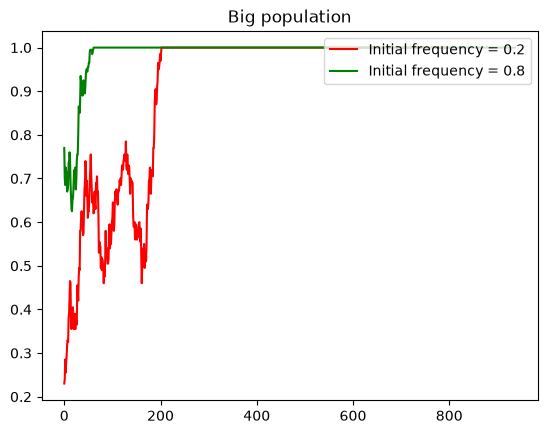

In [27]:
#Testing the model with big population and different initial frequencies
test1 = simulate_population(population_size=population_size,initial_frequency=0.2)
plt.plot(test1, label=f"Initial frequency = 0.2", c='r')

test1 = simulate_population(population_size=population_size,initial_frequency=0.8)
plt.plot(test1, label=f"Initial frequency = 0.8", c='g')

plt.title("Big population")
plt.legend(loc="upper right")
plt.show()

As expected, in the smaller population initial frequency doesn't directly determine wheteher a gene is more likely to spred or disappear as random genetic drift can easily override it. In larger populations alleles with higher initial frequencies are more likely to become fixed. Also, in smaller populations genetic drift plays a crucial role in allele spreading and selection strength's advantage can be easily lost. Meanwhile, in bigger populations the noise is smaller and an allele with higher fitness gradually increases its percent of population.<br> What is more interesting to investigate is changing the initial frequency and the selection strength in order to see what is more important - higher count of alleles in the first generation or better adaptation to the environment. What is expected to see is that higher fitness has a priority over higher initial frequency, since it allows better allele spread in the next generations. That means that allele with higher fitness will become fixed more often, while the one with higher initial frequency will become extinct in most of the simulations.

Low initial frequency and high selection strength
Chance of fixation: 1.0
Chance of extinction: 0.0
High initial frequency and low selection strength
Chance of fixation: 0.7
Chance of extinction: 0.18


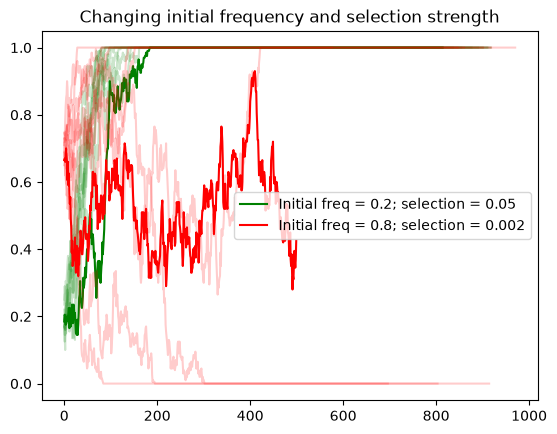

In [74]:
fixation_case1 = 0
extinction_case1 = 0
simulations = 100
print("Low initial frequency and high selection strength")
for simulation_case1 in range(simulations):
    low_freq_high_selection = simulate_population(population_size=population_size,initial_frequency=0.2,selection=0.05)
    if(low_freq_high_selection[-1]==1):
        fixation_case1 += 1
    elif(low_freq_high_selection[-1]==0):
        extinction_case1 += 1
    if simulation_case1 < 10:
        if simulation_case1 == 0:
            plt.plot(low_freq_high_selection, c='g', label="Initial freq = 0.2; selection = 0.05")
        else:
            plt.plot(low_freq_high_selection, c='g', alpha=0.2)
print(f"Chance of fixation: {fixation_case1/simulations}")
print(f"Chance of extinction: {extinction_case1/simulations}")


fixation_case2 = 0
extinction_case2 = 0
print("High initial frequency and low selection strength")
for simulation_case2 in range(simulations):
    high_freq_low_selection = simulate_population(population_size=population_size,initial_frequency=0.7,selection=0.002)
    if(high_freq_low_selection[-1]==1):
            fixation_case2 += 1
    elif(high_freq_low_selection[-1]==0):
            extinction_case2 += 1
    if simulation_case2 < 10:
        if simulation_case2 == 0:
            plt.plot(high_freq_low_selection, c='r', label="Initial freq = 0.8; selection = 0.002")
        else:
            plt.plot(high_freq_low_selection, c='r', alpha=0.2)
print(f"Chance of fixation: {fixation_case2/simulations}")
print(f"Chance of extinction: {extinction_case2/simulations}")
plt.xlabel="Number of generation"
plt.ylabel="Allele frequency"
plt.title("Changing initial frequency and selection strength")
plt.legend()
plt.show()

By carefully observing the plot in several simulations, turns out that my initial assumption was partially wrong (or at least it has dropped out the main rule that in a closed population every allele becomes fixed or extinct after a period of time and the initial frequency is the foundational probability of fixation). In both scenarios allele ***A*** becomes fixed in most of the cases due to initial frequency determining this chance(as mentioned in [[5]](#ref5)). In the case where allele initial frequency is high, but fitness is low, the graphical representation of the process fluctates in more generations (respectively longer in time) after eventually reaching fixation. But it doesn't become extinct more often as previously assumed. At the same time allele with low initial frequency and high fitness reaches fixation in fewer generations while allele frequency gradually raises. Calculating the times of fixation and extinction shows us that alleles with higher selection strength are more likely to get fixed than those who have higher initial frequency. The graphical representation shows that the difference between initial frequency and allele fitness influence not only the result (fization/extinction) but also the time it takes to be reached.

### 13. Analyzing results

#### 13.1 Deterministic or stochastic model
Starting with the difference between deterministic and stochastic models, it is evident that the stochastic model is the one that better simulates the spread of an allele across generations. Real-world proccesses, as I mentioned already, involve randomness and unexpected events that are not captured by deterministic models. However, the stochastic model is still a simplified mathematical model and does not include every biological factor that affects evolution. 

| Feature | Deterministic model | Stochastic model |
| :--- | :--- | :--- |
| Randomness | Not included | Included |
| Genetic drift | Not included | Included |
| Allele frequency | Follows a fixed rule | Fluctates between generations |
| Prediction | Gives a fixed trajectory under my model assumptions | Gives possible trajectories depending on initial conditions that change over time |
| Fixation/extinction | Does not occut from drift alone | May occur due to genetic drift |

#### 13.2 Factors affecting allele production
Using the stochastic model, the following parameter were observed in different situations: initial allele frequency, population size and allele fitness as these are the main factors that allele spread depends on. 
>* Population size <br> 
Smaller populations are more sensitive to the factors that affect evolution such as initial frequency, allele fitness and random events that alter allele frequencies (like genetic bottlenecks). Allele frequency fluctates more wildely as it is strongly driven by genetic drift. Meanwhile the process in larger populations is more predictable and governed by mathematical rules. The large number of individuals makes it difficult for  randomness to cause significant changes in allele frequency over a short period of time. <br><br>
>* Initial allele frequency <br>
Determines the probability of allele fixation. It has a particulary visible effect in large populations, where the frequency in each subsequent generation is close to the initial proportion of allele ***A***. An allele with a high initial frequency also has a high chance of becoming fixed over time. Therefore, if its fitness is high as well, fixation will occur after a significantly shorter period of time rather than it would for an allele with a high initial frequency but low fitness. <br><br>
>* Allele fitness <br>
Better adaptation to the environment increases the posibility allele's fixation, as it's naturally favored over alleles with lower fitness. However, in small populations this advantage can be easily lost due to genetic drift, whereas in bigger populations allele with higher fitness becomes fixed more consistently. High allele fitness increases the chance of fixation regardless of the initial frequency, while low fitness of an allele with higher initial frequency can lead to extinction more often.


### 14. Project application and target audience

#### 14.1 Where can these models be used?
Mathematical models of allele frequency changes have application in biology, medicine and evolutonary research by helping to understand how evolutionary forces affect populations. For example the United States Geological Survey has published and package for the programming language R [[6]](#ref6), designed to simulate genetic consequences of population redductions, catastrophes driven by stochastic forces and so on. Such models also help researches to investigate why certain genetic variants are more common in some populations. By running simulations under changing conditions, scientists may compare allele evolution across generations.

#### 14.2 Working solutions
The ideas explored in my project are used in many software applications such as:
>* [Population Genetics Explorer — HHMI BioInteractive](https://www.biointeractive.org/classroom-resources/population-genetics-explorer) 
<br> An interactive simulator that allows users to investigate allele frequency reflected by selection, mutation, migration and other parameters by choice.
>* [Allele Tracker — evo-edu.org](https://evo-edu.org/apps/allele-tracker/) 
<br> This web application also provides information about allele frequency together with a helpful user guide for new learners.

#### 14.3 MathGene target audience
The audience that my project targets is learners with no prior experience. Its main aim is to be suitable for both learners in biology and mathematics (statistics and probability). Therefore it requires no advanced knowledge either in Python programming or in biological concepts and keeps both the code and the scientific explanations simple. In this way learners may focus on the conceptual idea itself rather than struggling with the technical implementation.

#### 14.4 Future improvements
The model developed in my project has several limitations such as assuming a simplified diploid population, not including every biological factor that may affect reproduction and not using genetic data from a specific species. Future versions could include mutation, migration and real genetic data. Such improvements would make model's simulations more biologically realistic and provide a better representation of what naturally happens during evolution. 

### Resources
<a id="ref1"></a>1. Fowler, Samantha, et al. "11.2 Mechanisms of Evolution." Concepts of Biology, OpenStax, 25 Apr. 2013, https://openstax.org/books/concepts-biology/pages/11-2-mechanisms-of-evolution. Accessed [09 Oct. 2026]. <br>
<a id="ref2"></a>2. Khan Academy. "Allele frequency and the gene pool." Biology, Khan Academy, https://www.khanacademy.org/science/biology/her/heredity-and-genetics/a/allele-frequency-the-gene-pool. Accessed [09 Oct. 2026]. <br>
<a id="ref3"></a>3. "Binomial distribution." Wikipedia, The Free Encyclopedia, Wikimedia Foundation, [11 September 2026], https://en.wikipedia.org/wiki/Binomial_distribution. Accessed [10 October 2026]. <br>
<a id="ref4"></a>4. Khan Academy. "Genetic drift." Biology, Khan Academy, https://bg.khanacademy.org/science/ap-biology/natural-selection/population-genetics/a/genetic-drift-founder-bottleneck. Accessed [20 Oct. 2026]. <br>
<a id="ref5"></a>5. Pritchard, J. K. (2023). "Genetic drift." In "An Owner's Guide to the Human Genome" Stanford University, https://web.stanford.edu/group/pritchardlab/HGbook/Release-2023-09/HGBook-2023-09-chapters/HGBook-2023-09-23-ch2.1.pdf. Accessed [20 Oct. 2026].<br>
<a id="ref6"></a>6. U.S. Geological Survey. "Cgsim: An R package for simulation in population genetics, conservation, and management". U.S. Geological Survey,https://www.usgs.gov/publications/cgsim-r-package-simulation-population-genetics-conservation-and-management. Accessed [24 Oct. 2026].
